# 05 · Distribuciones no elípticas (E5)

Los cuadernos anteriores usan distribuciones normales, que son elípticas: sus regiones de profundidad son elipses y
la longitud de ruta media ordena las observaciones de forma parecida a la profundidad de Tukey. En este cuaderno
estudiamos qué ocurre cuando la distribución no es elíptica. El experimento E5 incluye, con $n = 1000$:

- **colas pesadas**: la $t$ de Student elíptica con $\nu \in \{1, 3, 10\}$ grados de libertad y matriz de dispersión
  $\Sigma_0 = \left(\begin{smallmatrix} 1 & 0.5 \\ 0.5 & 1 \end{smallmatrix}\right)$, que sigue siendo elíptica pero
  tiene colas mucho más pesadas que la normal ($\nu = 1$ es la distribución de Cauchy);
- **asimetría**: la log-normal $\exp(\mathbf{Y})$, componente a componente, con $\mathbf{Y} \sim N_2(\mathbf{0}, s^2\Sigma_0)$
  y $s \in \{0.5, 1\}$;
- **multimodalidad**: las mezclas $\frac{1}{2} N((-\delta, 0), I) + \frac{1}{2} N((\delta, 0), I)$ con
  $\delta \in \{0, 1.5, 3\}$ (unimodal, casi bimodal y bimodal) y la mezcla desigual $0.8\, N((-3, 0), I) + 0.2\, N((3, 0), I)$;
- **soporte no convexo**: un anillo de radio $3$, con ángulo uniforme y ruido radial $N(0, 0.3^2)$.

Las colas pesadas y la asimetría se estudian con $100$ réplicas y las mezclas y el anillo con $50$. En las
distribuciones no elípticas no hay una expresión explícita de $HD(\mathbf{x}, P)$, que se aproxima con una muestra de
referencia de $20\,000$ observaciones. En las mezclas y en el anillo comparamos además la longitud de ruta con la
**densidad** verdadera.

In [1]:
import random
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "../src")
from isolation_forest import iforest, longitudes
from eif import eif, longitudes_eif
from escenarios import MezclaNormal, Anillo
from profundidad import hd_muestral
import visualizacion as V

PSI, T, HLIM = 256, 100, 255
pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)
E5 = pd.read_csv("../results/E5.csv")

## Resultados sobre las réplicas

La figura muestra la $\tau_b$ media entre la longitud de ruta media y $HD(\cdot, P_n)$ en cada escenario, junto con el
techo.

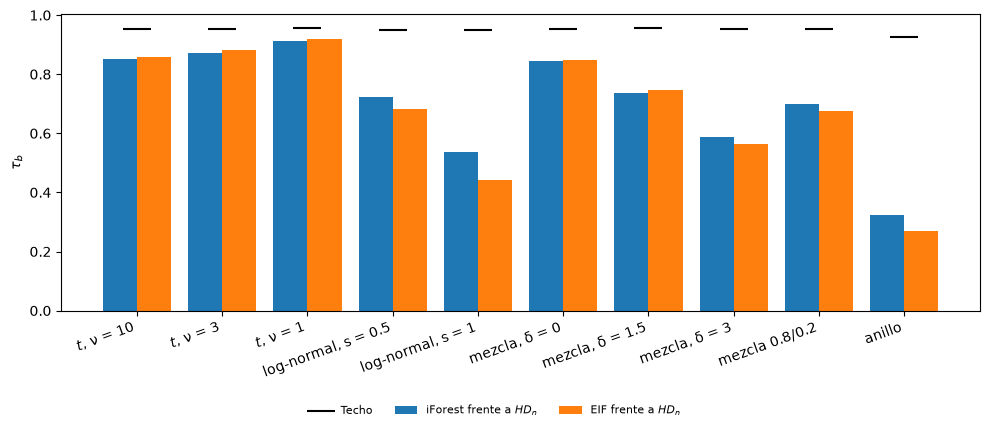

In [2]:
ESCENARIOS = ["E5 t nu=10", "E5 t nu=3", "E5 t nu=1", "E5 lognormal s=0.5", "E5 lognormal s=1.0",
              "E5 mezcla delta=0.0", "E5 mezcla delta=1.5", "E5 mezcla delta=3.0", "E5 mezcla 0.8/0.2 delta=3",
              "E5 anillo"]
NOMBRES = ["$t$, ν = 10", "$t$, ν = 3", "$t$, ν = 1", "log-normal, s = 0.5", "log-normal, s = 1",
           "mezcla, δ = 0", "mezcla, δ = 1.5", "mezcla, δ = 3", "mezcla 0.8/0.2", "anillo"]
fig = V.dibujar_barras(E5, ESCENARIOS, NOMBRES)
V.guardar(fig, "E5_tau")
plt.show()

In [3]:
V.tabla_resumen(E5).reindex(ESCENARIOS, level=0)

R       $\tau_b$       $\rho_S$     $r_{\log}$        $\xi_n$ Solapamiento 5 % $\tau_b$ centro $\tau_b$ periferia
escenario                 método                                                                                                                      
E5 t nu=10                Techo    100  0.954 (0.011)  0.997 (0.001)  0.988 (0.005)  0.925 (0.016)    0.891 (0.034)   0.911 (0.027)      0.843 (0.036)
                          iForest  100  0.852 (0.016)  0.968 (0.008)  0.975 (0.004)  0.779 (0.023)    0.822 (0.040)   0.618 (0.057)      0.751 (0.036)
                          EIF      100  0.857 (0.017)  0.970 (0.008)  0.977 (0.004)  0.787 (0.023)    0.859 (0.036)   0.628 (0.062)      0.791 (0.037)
E5 t nu=3                 Techo    100  0.954 (0.013)  0.997 (0.002)  0.990 (0.004)  0.925 (0.019)    0.907 (0.034)   0.907 (0.032)      0.861 (0.034)
                          iForest  100  0.873 (0.017)  0.976 (0.007)  0.981 (0.003)  0.809 (0.024)    0.858 (0.040)   0.669 (0.057)      0.790 (0.026)
                          EIF      100  0.881 (0.017)  0.978 (0.007)  0.983 (0.003)  0.821 (0.023)    0.890 (0.035)   0.682 (0.056)      0.824 (0.030)
E5 t nu=1                 Techo    100  0.955 (0.014)  0.997 (0.002)  0.992 (0.004)  0.927 (0.021)    0.923 (0.036)   0.904 (0.032)      0.880 (0.038)
                          iForest  100  0.911 (0.013)  0.988 (0.004)  0.984 (0.003)  0.864 (0.019)    0.901 (0.032)   0.772 (0.039)      0.845 (0.025)
                          EIF      100  0.918 (0.013)  0.990 (0.003)  0.985 (0.003)  0.873 (0.018)    0.917 (0.032)   0.785 (0.036)      0.867 (0.029)
E5 lognormal s=0.5        Techo    100  0.951 (0.013)  0.996 (0.002)  0.985 (0.004)  0.921 (0.020)    0.875 (0.038)   0.909 (0.031)      0.828 (0.033)
                          iForest  100  0.723 (0.040)  0.901 (0.029)  0.903 (0.018)  0.594 (0.053)    0.539 (0.052)   0.455 (0.091)      0.479 (0.041)
                          EIF      100  0.681 (0.031)  0.872 (0.025)  0.870 (0.017)  0.535 (0.041)    0.501 (0.041)   0.413 (0.077)      0.390 (0.040)
E5 lognormal s=1.0        Techo    100  0.950 (0.014)  0.996 (0.002)  0.984 (0.005)  0.919 (0.022)    0.874 (0.035)   0.904 (0.035)      0.827 (0.036)
                          iForest  100  0.537 (0.041)  0.738 (0.045)  0.756 (0.026)  0.350 (0.045)    0.448 (0.038)   0.279 (0.066)      0.288 (0.032)
                          EIF      100  0.443 (0.031)  0.618 (0.042)  0.668 (0.024)  0.241 (0.033)    0.449 (0.036)   0.229 (0.049)      0.229 (0.029)
E5 mezcla delta=0.0       Techo     50  0.954 (0.012)  0.997 (0.002)  0.986 (0.004)  0.925 (0.019)    0.885 (0.039)   0.914 (0.029)      0.836 (0.035)
                          iForest   50  0.846 (0.022)  0.964 (0.011)  0.976 (0.004)  0.771 (0.028)    0.880 (0.032)   0.600 (0.073)      0.807 (0.029)
                          EIF       50  0.849 (0.021)  0.966 (0.011)  0.976 (0.004)  0.777 (0.026)    0.876 (0.038)   0.608 (0.074)      0.804 (0.032)
E5 mezcla delta=1.5       Techo     50  0.956 (0.011)  0.997 (0.001)  0.987 (0.005)  0.928 (0.017)    0.878 (0.037)   0.921 (0.023)      0.826 (0.044)
                          iForest   50  0.735 (0.034)  0.898 (0.025)  0.949 (0.010)  0.641 (0.038)    0.854 (0.045)   0.296 (0.088)      0.758 (0.032)
                          EIF       50  0.747 (0.035)  0.905 (0.026)  0.951 (0.011)  0.655 (0.039)    0.869 (0.036)   0.330 (0.099)      0.779 (0.032)
E5 mezcla delta=3.0       Techo     50  0.952 (0.012)  0.996 (0.002)  0.985 (0.006)  0.921 (0.018)    0.877 (0.038)   0.910 (0.028)      0.823 (0.043)
                          iForest   50  0.589 (0.027)  0.740 (0.026)  0.849 (0.015)  0.523 (0.028)    0.795 (0.039)   0.052 (0.057)      0.707 (0.030)
                          EIF       50  0.565 (0.031)  0.712 (0.030)  0.817 (0.021)  0.502 (0.037)    0.808 (0.041)   0.027 (0.058)      0.721 (0.035)
E5 mezcla 0.8/0.2 delta=3 Techo     50  0.954 (0.010)  0.997 (0.001)  0.986 (0.005)  0.926 (0.014)    0.883 (0.

La $\tau_b$ solo detecta relaciones crecientes. Para saber si, cuando la $\tau_b$ es baja, la longitud de ruta
media sigue dependiendo de la profundidad aunque no de forma creciente, representamos también el coeficiente
$\xi_n$ de Chatterjee, que mide en qué grado $\bar h_t$ es una función de $HD(\cdot, P_n)$, sea o no monótona
(véase el cuaderno 01). Si $\xi_n$ es claramente mayor que $\tau_b$, la relación existe pero no es creciente.

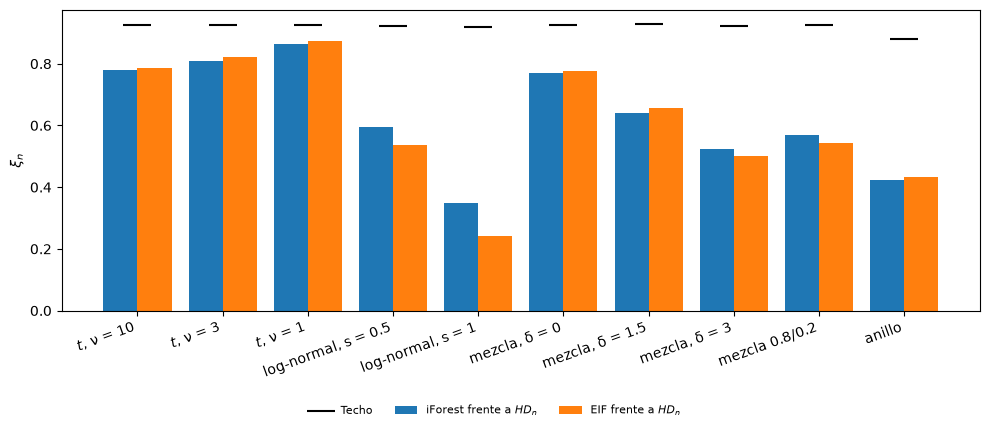

In [4]:
fig = V.dibujar_barras(E5, ESCENARIOS, NOMBRES, medida="xi")
V.guardar(fig, "E5_xi")
plt.show()

In [5]:
V.comparacion_pareada(E5, medidas=("tau_b", "xi", "sol05")).reindex(ESCENARIOS, level=0)

diferencia media réplicas a favor del EIF  p de Wilcoxon
escenario                 medida                                                                    
E5 t nu=10                $\tau_b$                     0.005                 60 / 100      2.243e-02
                          $\xi_n$                      0.008                 62 / 100      8.359e-03
                          Solapamiento 5 %             0.037                 79 / 100      4.419e-13
E5 t nu=3                 $\tau_b$                     0.008                 62 / 100      1.037e-03
                          $\xi_n$                      0.012                 59 / 100      2.825e-04
                          Solapamiento 5 %             0.032                 81 / 100      1.665e-12
E5 t nu=1                 $\tau_b$                     0.007                 68 / 100      5.134e-06
                          $\xi_n$                      0.009                 65 / 100      1.620e-05
                          Solapamiento 5 %             0.016                 63 / 100      2.865e-07
E5 lognormal s=0.5        $\tau_b$                    -0.042                 18 / 100      1.447e-12
                          $\xi_n$                     -0.059                 18 / 100      1.480e-13
                          Solapamiento 5 %            -0.038                 13 / 100      1.857e-11
E5 lognormal s=1.0        $\tau_b$                    -0.094                  1 / 100      4.016e-18
                          $\xi_n$                     -0.108                  0 / 100      3.897e-18
                          Solapamiento 5 %             0.001                 31 / 100      5.061e-01
E5 mezcla delta=0.0       $\tau_b$                     0.004                  27 / 50      3.777e-01
                          $\xi_n$                      0.006                  30 / 50      2.823e-01
                          Solapamiento 5 %            -0.004                  25 / 50      5.572e-01
E5 mezcla delta=1.5       $\tau_b$                     0.012                  29 / 50      6.930e-02
                          $\xi_n$                      0.014                  29 / 50      4.610e-02
                          Solapamiento 5 %             0.015                  32 / 50      3.283e-02
E5 mezcla delta=3.0       $\tau_b$                    -0.024                  13 / 50      2.555e-05
                          $\xi_n$                     -0.021                  12 / 50      1.363e-04
                          Solapamiento 5 %             0.013                  27 / 50      8.025e-02
E5 mezcla 0.8/0.2 delta=3 $\tau_b$                    -0.022                  17 / 50      1.558e-04
                          $\xi_n$                     -0.027                  17 / 50      9.041e-05
                          Solapamiento 5 %            -0.025                  12 / 50      1.660e-03
E5 anillo                 $\tau_b$                    -0.055                   1 / 50      1.243e-14
                          $\xi_n$                      0.007                  28 / 50      2.737e-01
                          Solapamiento 5 %             0.078                  42 / 50      1.387e-08

En las mezclas y en el anillo, la figura siguiente compara la concordancia de la longitud de ruta media con la
profundidad de Tukey y con la densidad verdadera.

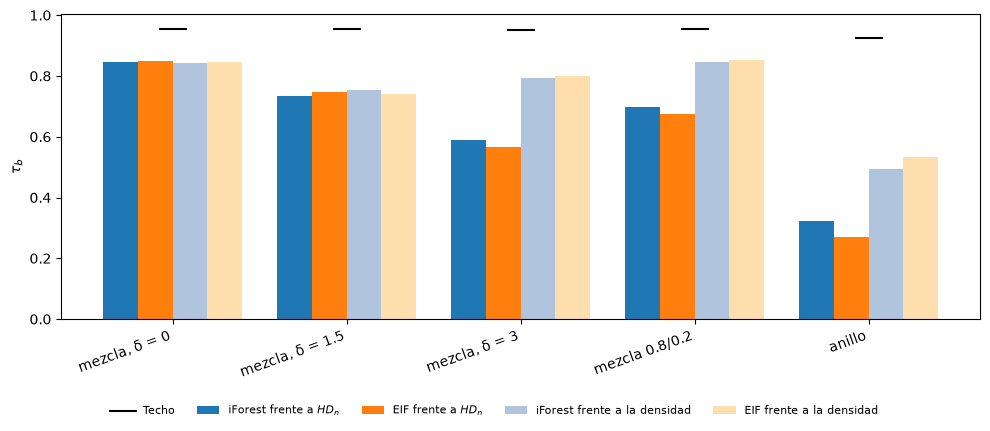

In [6]:
fig = V.dibujar_barras(E5, ESCENARIOS[5:], NOMBRES[5:], referencias=("HD_n", "densidad"))
V.guardar(fig, "E5_densidad")
plt.show()

## Una réplica: mezcla bimodal y anillo

Para entender estos resultados representamos, en la primera réplica (semilla $5000$) de la mezcla con $\delta = 3$ y
del anillo, la longitud de ruta media de los dos métodos, la profundidad de Tukey y la densidad, evaluadas en una
malla de puntos. Los mapas se representan por rangos: las zonas claras son las más centrales según cada medida.

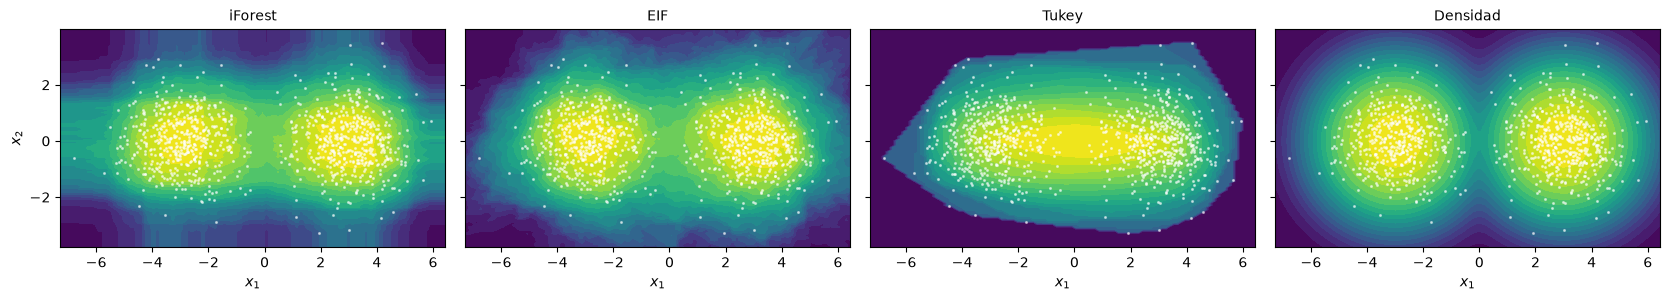

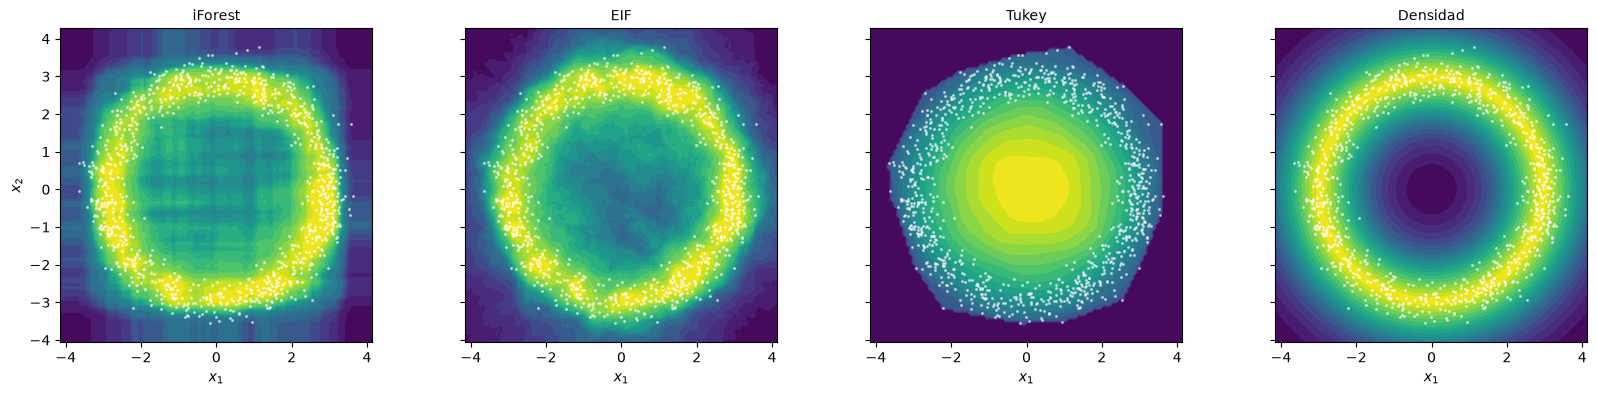

In [7]:
semilla = 5000
for esc, archivo in ((MezclaNormal("E5 mezcla delta=3.0", 1000, 3.0), "E5_mapas_mezcla"),
                     (Anillo("E5 anillo", 1000), "E5_mapas_anillo")):
    X, _ = esc.muestrear(np.random.default_rng(semilla))
    G, x, y = V.malla(X, puntos=100)
    random.seed(semilla)
    h_if = longitudes(G, iforest(X, t=T, psi=PSI), HLIM).mean(axis=1)
    random.seed(semilla)
    h_eif = longitudes_eif(G, eif(X, t=T, psi=PSI), HLIM).mean(axis=1)
    mapas = {"iForest": h_if, "EIF": h_eif, "Tukey": hd_muestral(X, G), "Densidad": esc.densidad(G)}
    fig = V.dibujar_mapas_malla(X, x, y, mapas)
    V.guardar(fig, archivo)
    plt.show()

En el anillo, la figura siguiente compara directamente la longitud de ruta media de las observaciones con
su profundidad de Tukey, en las dos escalas del cuaderno 01 (rangos arriba; valores con $HD$ en escala logarítmica
abajo). Si la longitud de ruta fuese una función creciente de la profundidad, los puntos seguirían la diagonal o la
recta; si depende de la profundidad pero no de forma creciente, dibujarán una curva que sube y después baja.

C:\Users\pablo\Downloads\TFGMatematicas\subir-repo-nuevo\notebooks\../src\visualizacion.py:196: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ejes[0, j].legend(loc="lower right")


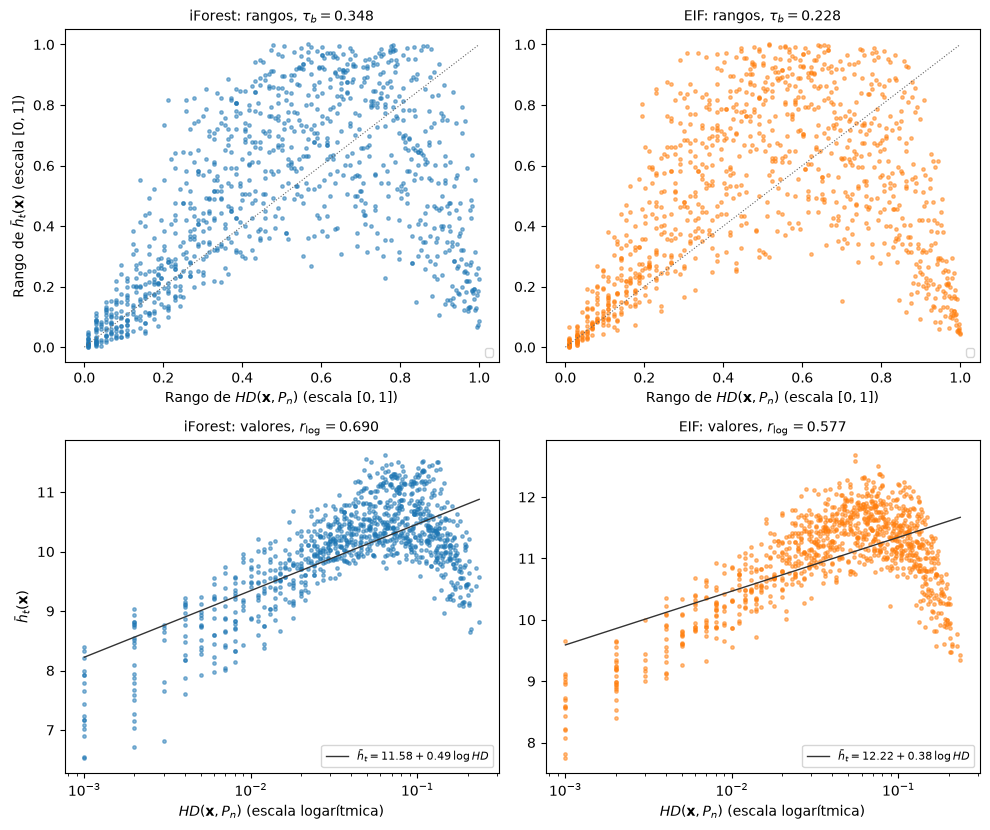

In [8]:
esc = Anillo("E5 anillo", 1000)
X, _ = esc.muestrear(np.random.default_rng(semilla))
hd = hd_muestral(X)
h = {}
random.seed(semilla)
h["iForest"] = longitudes(X, iforest(X, t=T, psi=PSI), HLIM).mean(axis=1)
random.seed(semilla)
h["EIF"] = longitudes_eif(X, eif(X, t=T, psi=PSI), HLIM).mean(axis=1)
fig = V.dibujar_h_frente_hd(h, hd)
V.guardar(fig, "E5_anillo_h_frente_hd")
plt.show()

## Observaciones

- **Con colas pesadas, la relación se mantiene e incluso mejora.** En la $t$ de Student, que sigue siendo elíptica,
  la $\tau_b$ es de $0.85$ con $\nu = 10$, $0.87$–$0.88$ con $\nu = 3$ y $0.91$–$0.92$ con $\nu = 1$ (la Cauchy), y
  $\xi_n$ está entre $0.78$ y $0.87$. Con colas más pesadas, las observaciones periféricas están más separadas del
  resto y se aíslan con más claridad. El EIF reproduce mejor la cola que iForest (solapamiento del $5\,\%$ de $0.92$
  frente a $0.90$ con $\nu = 1$, y de $0.86$ frente a $0.82$ con $\nu = 10$), lo que es coherente con la correlación
  $0.5$ de la matriz de dispersión.
- **La asimetría reduce mucho la concordancia.** En la log-normal, la $\tau_b$ baja a $0.72$ (iForest) y $0.68$ (EIF)
  con $s = 0.5$, y a $0.54$ y $0.44$ con $s = 1$. $\xi_n$ es todavía menor ($0.35$ y $0.24$ con $s = 1$): la longitud
  de ruta no es una función de la profundidad, porque observaciones con la misma profundidad se aíslan con muy
  distinta facilidad según estén en la zona densa, cerca de la moda, o en la cola. Aquí el EIF es peor que iForest.
- **Con varias modas, la longitud de ruta sigue a la densidad y no a la profundidad.** En la mezcla, la $\tau_b$ baja
  de $0.85$ con $\delta = 0$ a $0.74$ con $\delta = 1.5$ y a $0.57$–$0.59$ con $\delta = 3$. Con $\delta = 3$, tanto
  la $\tau_b$ ($0.79$–$0.80$) como $\xi_n$ ($0.70$–$0.71$) son mucho mayores con la densidad que con la profundidad
  ($0.57$–$0.59$ y $0.50$–$0.52$). En los mapas, la profundidad de Tukey es máxima entre las dos modas, donde apenas
  hay observaciones, mientras que la longitud de ruta es máxima en cada moda, como la densidad.
- **En el anillo la relación existe, pero no es creciente.** La $\tau_b$ es de $0.32$ (iForest) y $0.27$ (EIF), y en
  el centro es **negativa** ($-0.36$ y $-0.41$). Es el único escenario en que $\xi_n$ ($0.43$) supera a $\tau_b$, y la
  figura de la longitud de ruta frente a la profundidad muestra por qué: la relación tiene forma de U invertida. Las
  observaciones exteriores siguen la relación creciente habitual, pero las del borde interior, que son las más
  profundas según Tukey, son de las más fáciles de aislar, porque a su lado está el hueco central.
- **Conclusión.** La longitud de ruta media se parece a la profundidad de Tukey cuando la distribución es elíptica
  (unimodal y simétrica), y deja de hacerlo cuando no lo es. No se trata de un problema de estimación que se pueda
  corregir con más árboles o con otros parámetros: las regiones de profundidad de Tukey son siempre convexas, y el
  aislamiento no tiene esa restricción. Las medidas distinguen dos tipos de fallo: en el anillo la dependencia es no
  monótona ($\xi_n > \tau_b$), y en la log-normal la longitud de ruta apenas está determinada por la profundidad
  ($\xi_n$ bajo).